# 06 - Model Comparison
**Owner:** Sriniket Deeduvanu

This notebook compares the four models (KNN, neural network, random forest, gradient boosting) using the metrics that each model's notebook saved to `results/metrics/`. It does not retrain anything, so it runs in seconds. Notebooks 02 to 05 must be run first. All models were trained on the same stratified 80/20 split and evaluated on the same validation buildings.

In [1]:
import os, sys
from pathlib import Path

# --- Colab only: clone the repo and move into it ---
REPO = "ML-Project-Earthquake-Damage"
GITHUB_URL = "https://github.com/ayaanGH06/ML-Project-Earthquake-Damage.git"  # private repo: use a token URL in Colab, never commit it

if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists(REPO):
        !git clone {GITHUB_URL}
    %cd {REPO}
    !pip install -q -r requirements.txt

# --- Local Jupyter: notebooks run from notebooks/, so go up to the repo root ---
if Path.cwd().name == "notebooks":
    os.chdir("..")

# --- Data: the 3 CSVs must be in data/raw/ (see README for the download link) ---
DATA_DIR = Path("data/raw")
needed = ["train_values.csv", "train_labels.csv", "test_values.csv"]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {DATA_DIR.resolve()}. "
        "Download them from the Google Drive link in the README and place them in data/raw/."
    )

from src.data import load_raw, train_val_split, build_scaled_preprocessor, build_tree_preprocessor
from src.evaluate import evaluate_model, micro_f1

X, y, X_test = load_raw(DATA_DIR)
X_train, X_val, y_train, y_val = train_val_split(X, y)
print(X_train.shape, X_val.shape)

(208480, 38) (52121, 38)


## 1. Summary table

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

METRIC_DIR = Path("results/metrics")
FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "knn": "KNN",
    "neural_network": "Neural network",
    "random_forest": "Random forest",
    "gradient_boosting": "Gradient boosting",
}
majority_baseline = y_val.value_counts(normalize=True).max()

records = []
for key, label in MODELS.items():
    path = METRIC_DIR / f"{key}.json"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run the notebook for '{label}' first.")
    m = json.load(open(path))
    if "per_class" not in m:
        raise ValueError(f"{path.name} has no per-class metrics. "
                         f"Re-run the {label} notebook with the current src/evaluate.py.")
    records.append({
        "key": key, "model": label,
        "micro_f1": m["val_micro_f1"], "macro_f1": m["val_macro_f1"],
        "recall_grade_1": m["per_class"]["1"]["recall"],
        "recall_grade_2": m["per_class"]["2"]["recall"],
        "recall_grade_3": m["per_class"]["3"]["recall"],
        "precision_grade_1": m["per_class"]["1"]["precision"],
        "precision_grade_2": m["per_class"]["2"]["precision"],
        "precision_grade_3": m["per_class"]["3"]["precision"],
    })

summary = pd.DataFrame(records).sort_values("micro_f1", ascending=False).reset_index(drop=True)
print(f"Majority-class baseline (micro-F1): {majority_baseline:.4f}\n")
display(summary.drop(columns="key").round(4))

Majority-class baseline (micro-F1): 0.5689



,model,micro_f1,macro_f1,recall_grade_1,recall_grade_2,recall_grade_3,precision_grade_1,precision_grade_2,precision_grade_3
0,Gradient boosting,0.7459,0.6929,0.5218,0.8522,0.6296,0.6864,0.7436,0.7671
1,Random forest,0.7314,0.6645,0.4468,0.8637,0.5885,0.6870,0.7227,0.7652
2,Neural network,0.6972,0.6328,0.4372,0.8150,0.5720,0.6249,0.7052,0.6960
3,KNN,0.6802,0.6066,0.4016,0.8226,0.5185,0.5995,0.6849,0.6880


## 2. Overall performance

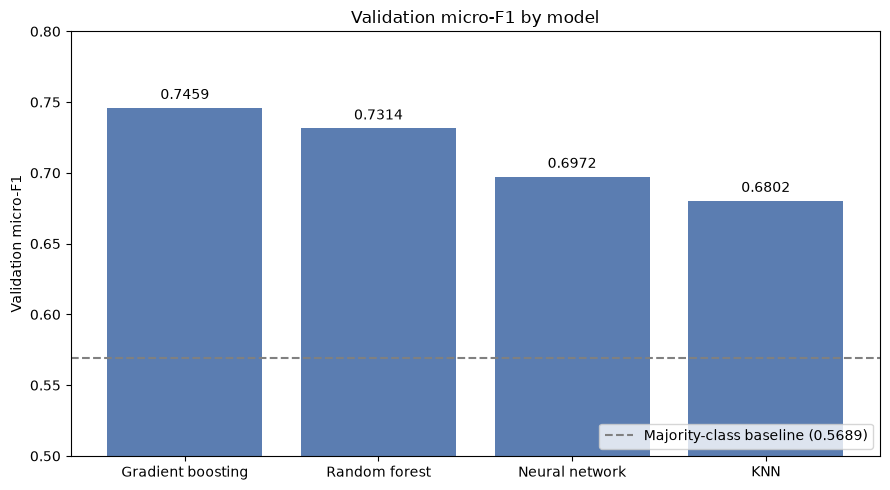

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(summary["model"], summary["micro_f1"], color="#5b7db1")
ax.axhline(majority_baseline, ls="--", lw=1.5, color="grey",
           label=f"Majority-class baseline ({majority_baseline:.4f})")
ax.set_ylabel("Validation micro-F1")
ax.set_title("Validation micro-F1 by model")
ax.set_ylim(0.50, 0.80)
for b, s in zip(bars, summary["micro_f1"]):
    ax.text(b.get_x() + b.get_width() / 2, s + 0.004, f"{s:.4f}", ha="center", va="bottom")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_micro_f1_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Performance per damage grade

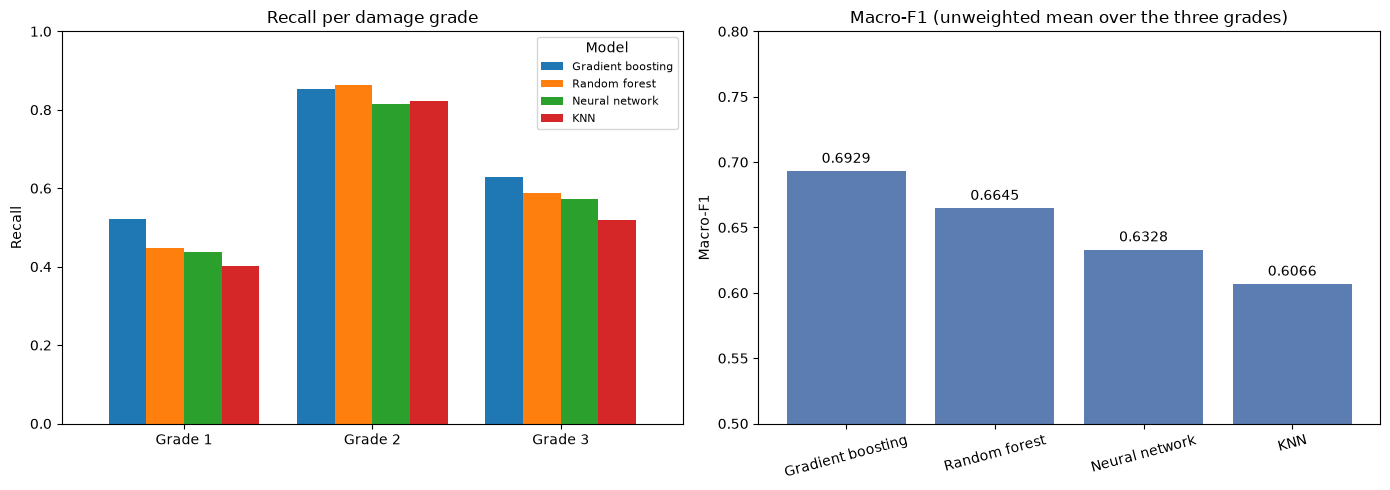

In [4]:
recall = summary.set_index("model")[["recall_grade_1", "recall_grade_2", "recall_grade_3"]]
recall.columns = ["Grade 1", "Grade 2", "Grade 3"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
recall.T.plot(kind="bar", ax=axes[0], width=0.8)
axes[0].set_title("Recall per damage grade")
axes[0].set_ylabel("Recall")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Model", fontsize=8)

bars = axes[1].bar(summary["model"], summary["macro_f1"], color="#5b7db1")
axes[1].set_title("Macro-F1 (unweighted mean over the three grades)")
axes[1].set_ylabel("Macro-F1")
axes[1].set_ylim(0.50, 0.80)
for b, s in zip(bars, summary["macro_f1"]):
    axes[1].text(b.get_x() + b.get_width() / 2, s + 0.004, f"{s:.4f}", ha="center", va="bottom")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(FIG_DIR / "06_per_class_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Confusion matrices

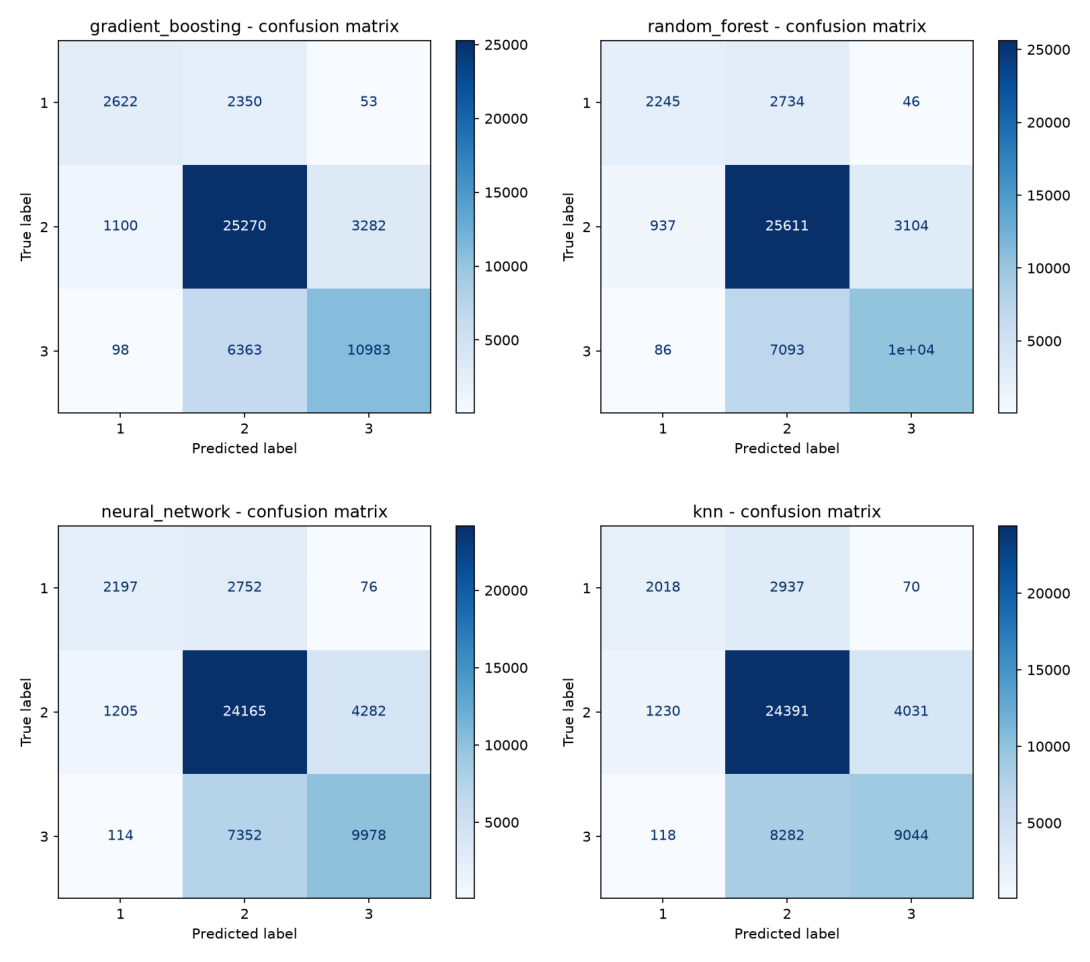

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (_, row) in zip(axes.ravel(), summary.iterrows()):
    ax.imshow(mpimg.imread(FIG_DIR / f"{row['key']}_confusion.png"))
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Feature importance (tree models)
Permutation importance measures how much a model's validation micro-F1 drops when one input column is shuffled. A larger drop means the model relies more on that feature. It describes predictive usefulness, not causal effects. The error bars show the standard deviation over the repeats.

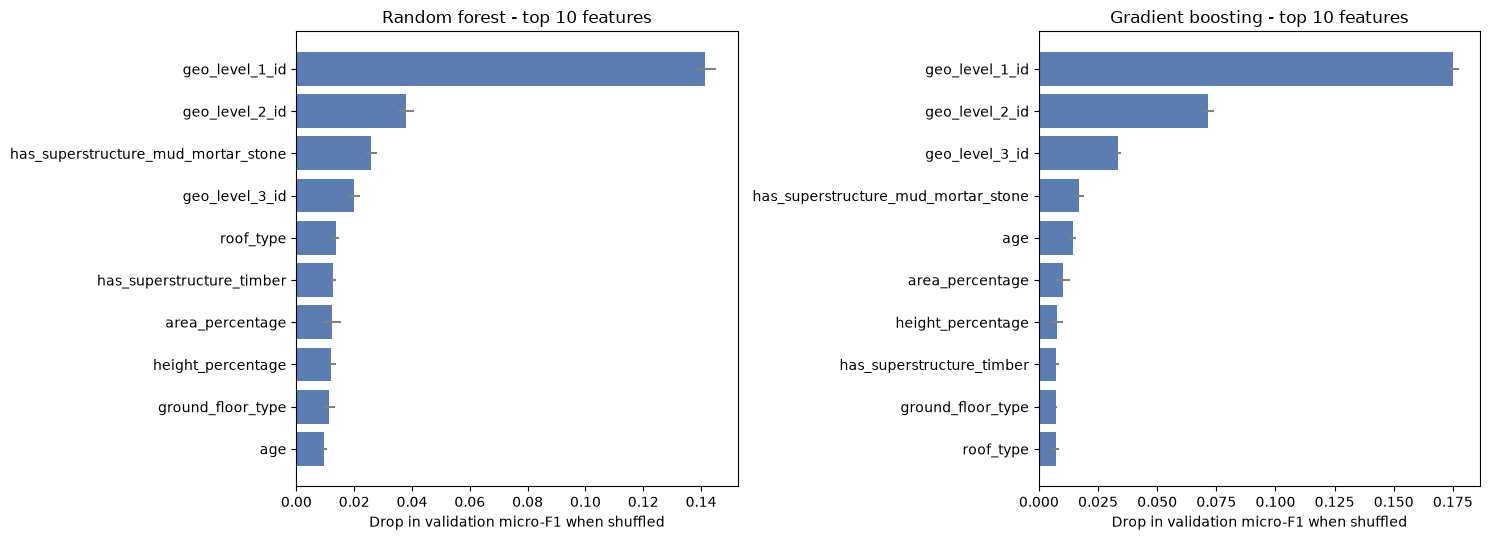

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, key in zip(axes, ["random_forest", "gradient_boosting"]):
    fi = json.load(open(METRIC_DIR / f"{key}_feature_importance.json"))
    mean = pd.Series(fi["importance_mean"]).nlargest(10).sort_values()
    std = pd.Series(fi["importance_std"])[mean.index]
    ax.barh(mean.index, mean.values, xerr=std.values, color="#5b7db1", ecolor="grey")
    ax.set_title(f"{MODELS[key]} - top 10 features")
    ax.set_xlabel("Drop in validation micro-F1 when shuffled")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Conclusions

**Ranking.** Gradient boosting is the best model (validation micro-F1 0.7459, macro-F1 0.6929), followed by the random forest (0.7314), the neural network (0.6972) and KNN (0.6802). All four are far above the majority-class baseline of 0.5689. The gaps between neighbouring models (0.015, 0.034 and 0.017) are several times larger than the sampling error of a validation set of this size (about 0.002), so the ranking is reliable on this split.

**Why the tree models win.** Permutation importance shows that the location columns are among the most important features for both tree models: `geo_level_1_id` by a wide margin, then `geo_level_2_id`, with `geo_level_3_id` and the superstructure material `has_superstructure_mud_mortar_stone` next. KNN and the neural network could not use `geo_level_2_id` and `geo_level_3_id` (they are dropped in the scaled preprocessing because one-hot encoding them would add around 13,000 columns), which likely accounts for much of their roughly 3 to 7 point gap to the tree models. Gradient boosting also beats the random forest while overfitting far less: its training-validation gap is 0.046 against 0.137.

**Performance per damage grade.** Every model is best on grade 2, the majority class (recall 0.82 to 0.86), and weakest on grade 1 (recall 0.40 to 0.52). Errors are mostly predictions of grade 2: the share of grade-3 buildings predicted as grade 2 falls from 47% for KNN to 36% for gradient boosting, and the share of grade-1 buildings from 58% to 47%. Confusing grades 1 and 3 is rare for every model (at most 118 buildings in either direction). Gradient boosting's advantage over the random forest comes mostly from the minority classes (recall 0.52 against 0.45 for grade 1 and 0.63 against 0.59 for grade 3).

**Limitations.** The hyperparameters were chosen on the validation split, so the scores are slightly optimistic, and the models were compared on a single split. About 6% of buildings repeat the features of an earlier building (notebook 01), which can favour high-capacity models such as a random forest with small leaves. All scores are validation scores and are not directly comparable with the competition test-set scores quoted in the CS229 report.

**Conclusion.** Gradient boosting (learning rate 0.1, 63 leaves per tree, early stopping at 350 iterations) is the recommended model for this problem. It has the best micro-F1 and macro-F1, a small training-validation gap, and the best recall on grade 3 (near-total destruction), the class that matters most for rescue planning.